# Online Retail Dataset Analysis
#### by Amanda Ang

### Introduction to the Online Retail Dataset

The Online Retail Dataset consists of transactional records from the UCI Machine Learning Repository. It is a transnational data set that contains all transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail (Chen, 2015). The company mainly sells unique all-occasion gifts. Many customers of the company are wholesalers.

To get a glance at the dataset, several steps must be done to load the dataset in the Jupyter Notebook. First, import the essential libraries such as Pandas, Numpy, Seaborn, and Matplotlib, with their respective conventional aliases. Importing libraries is imperative since each of these has its unique function and methods that are used for data manipulation, data visualization, numerical computation, and general plotting, which is to be used in later code blocks. 

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Second, in able to read the CSV file or the dataset, the ‘pd.read_csv’ function of Pandas is executed. 


In [7]:
retail = pd.read_csv("C:\\Users\\Amanda\\Downloads\\onlineretail.csv")

The ‘.shape’ attribute in NumPy represents the dataset as having 541,909 rows and 8 columns in total. 


In [9]:
retail.shape

(541909, 8)

It is observed that each row in the DataFrame shows a specific purchase transaction. On the other hand, the columns provide essential information for each transaction made within the online retail store. The ‘.head()’ method in Pandas displays the first five rows, giving a quick overview of its structure and content. 

In [11]:
retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 8:26,3.39,17850.0,United Kingdom


To identify the type of data each column contains or accepts, the ‘.dtypes’ object in Numpy is used. The columns ‘InvoiceNo’, ‘StockCode’, ‘InvoiceDate’, and ‘Country' are ‘object’ types. The ‘object’ data type in Pandas is typically used for text or string or when dealing with mixed data types. The columns ‘UnitePrice’ and ‘CustomerID’ contain a data type of ‘float64’. This means that it can store numbers with decimals or fractions. Lastly, the column ‘Quantity’ stores whole numbers without decimals. 

In [13]:
retail.dtypes

InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

In examining the values for each column in the DataFrame, the descriptions for each column are provided as follows: 
* **Invoice No.** - Invoice Number or ‘InvoiceNo’ is a 6-digit integral number uniquely assigned to each transaction. If the code starts with the letter 'c', it indicates a cancellation. An invoice number is assigned to each invoice in order to identify and track transactions, which is commonly entailed to each retail (Deora, 2023). * **StockCode** - It is a unique identifier that varies in a format wherein it includes combinations of a 5-digit number and a letter (e.g. 85123A) or solely a number (e.g. 23255). This identifier is assigned to each distinct product or item in the retail store’s catalog to track and manage inventory levels. * **Description** - It is typically the name of the product or the details for each product. This provides the context of which product is sold to the customer. * **Quantity** - It is the amount or the number of products that were bought on a particular transaction. * **InvoiceDate** - It is the timestamp of the date and time when a transaction was made or recorded in the system. 
* **UnitPrice** - It is the price per unit of the product being purchased. * **CustomerID** - It is a 5-digit unique identifier assigned to each customer to identify who completed a transaction. * **Country** - The name of the country where each customer resides or is located. 




The ‘.info’ function from Pandas provides a clear summary of each column in the DataFrame, such as its non-null values, number of columns, data types, and range index. There are a total of 541,909 entries, starting with 0 in the DataFrame. With that, it is apparent that the columns: ‘InvoiceNo’, ‘StockCode’, ‘Quantity’, ‘InvoiceDate’, ‘UnitePrice’, and ‘Country’ has no missing values. ‘Description’ and ‘CustomerID’ have 1,454 and 135,080 missing values respectively.

In [16]:
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


The ‘.describe()’ is used to provide summary statistics for the DataFrame. It provides a piece of clear information about count, mean, standard deviation, minimum and maximum, and percentiles (25%, 50%, 75%). The summary statistics reveal that the average quantity for each transaction made is around 9-10 items. The negative minimum quantity, 80,995, suggests that it can be the result of data entry errors, or data corruption, or may represent some adjustments or returns to previous sales in the retail. The standard deviation of 218 indicates high variability in quantities among transactions and also the maximum value is very high compared to all of the percentiles. It is noteworthy that the unit price has an average of approximately £4.61 with a standard deviation of 96.76, which shows variability. A negative minimum unit price of -11,062 seems odd and unusual, which could be a result of some business rules regarding pricing and discounts or simply due to data entry errors or corruption (Rastrullo, 2021). Similar to quantity, it has an outrageously high maximum value compared to the percentiles. 

In [18]:
retail.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


With the expressions 'isna().sum().sort_values(ascending=False)', it calculates the number of missing values for each column in the DataFrame and sorts them in descending order. This code is executed to determine which columns have missing data. It is evident that the ‘CustomerID’ column has 135,080 missing values, and the ‘Description’ column has 1,454 missing values.


In [20]:
retail.isna().sum().sort_values(ascending=False)

CustomerID     135080
Description      1454
InvoiceNo           0
StockCode           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

The code block imports the 'datetime' module to reconfigure the 'InvoiceDate' column into a 'datetime' data type or format. Additionally, the 'CustomerID' is treated as a string type so that the program can identify as a categorical variable. For the 'Description' column, it trims the extra spaces to improve the readability of the DataFrame. 

**Functionality and Benefits**

Transactional data represents the individual records of sales transactions that occur within the retail business (TIBCO, n.d.). Analyzing the transactional dataset is important in retail businesses since it supports the decision-making of the online retail business and will help them thrive in the competitive market. Aside from that, it is essential for operational efficiency, inventory management, and identification of trends and patterns in the data (Admin, 2024). A good example is market basket analysis. Market basket analysis uncovers patterns of which combinations of products or items are usually bought together (Amruta, 2021). Sales transactions would be a useful dataset to analyze the performance of the products or even the prices and such. With data-driven decision-making, online retail businesses will be able to make informed decisions, optimize processes, understand customers, and improve financial performance. 

Data analytics plays a vital role in the dataset. It can be applied in different ways according to the goal or the problem trying to solve by the organisation. It follows a step-by-step process that starts with data collection, data preparation, exploratory data analysis, data modeling, evaluation, and interpretation of results. Data analytics is implemented for different purposes. One common application is customer segmentation (Institute of Data, 2023). Customer segmentation is done by analysing customer behavior data like demographics, purchase history, and preferences to identify distinct customer groups with similar purchasing patterns (Saha, 2024). Second, data analytics can be applied to the set by optimizing the supply chain and inventory management (Institute of Data, 2023). This is to reduce the overstock or stockout scenarios and ensure that the products are readily available while maintaining minimized costs and maximized sales opportunities. Besides that, pricing strategy optimization can be done on the dataset in order to set effective prices on products to maximize revenue. A lot can be done with the dataset for continuous improvement of the online retail business, but it is important to keep in mind the objectives the organisation trying to achieve within the business. 

One of the advantages of data analytics for online retail businesses using this dataset is that it helps retailers understand past sales, optimize the present, and predict future sales (Tomar, 2020). The knowledge that retailers gain from leveraging data analytics allows them to make personalized marketing, and enhance customer experience, which would significantly lead to higher customer loyalty and satisfaction. In line with enhancing customer experience, the retail can identify top customers through customer segmentation and also they can tailor their marketing strategies that will resonate to the target audience better. Another is predictive analytics which is widely used for sales forecasting. This is done by analyzing historical data and considering different factors like customer behavior, promotions, seasonality, and more (Fuchs, 2020). Data analytics makes inventory forecasting valuable because the retailer can align inventory levels accordingly through historical data analysis. It assists retailers in identifying obsolete or slow-moving products which prompts them to take appropriate action like clearance sales or markdowns. Overall, data analytics has been increasingly beneficial and utilized in countless ways in this modern age of big data, especially in the realm of businesses. 


**Constraints**

Based on the dataset, a notable challenge is the missing values. Missing values are data points that are not stored for a particular variable in the dataset. It can negatively impact the performance of the machine learning model by creating a bias in the dataset. ‘Description’ and ‘CustomerID’ columns contain missing values which are critical information related to retail transactions. The ‘Description’ provides context about the product sold, while ‘CustomerID’ tracks the individual who bought the product. With that, it may affect the summary statistics and may distort the data visualizations generated from the analysis. 

Aside from data quality issues or incomplete data, the volume of data can be highly complex since online retail produces large amounts of data daily wherein each transaction contributes to the volume (Barron, 2024). As the data volume increases, the business must adapt and implement scalable solutions or systems for data analysis, processing, and storage. The volume may even rapidly increase and be more substantial when the customer base and sales grow throughout the years. In line with this, data cleaning will be a critical step to ensure the accuracy and integrity of the data despite its volume (removing duplicate records, null values, etc..) (Ansa, 2023). This is done to address the inconsistencies and ensure that the data is formatted correctly and standardized which would avoid skewing the results. 

Third, data privacy and security are a cornerstone in the age of digitalization. The personal information of customers and even the business itself is at stake without the proper measures to protect data from unauthorized access, insider threats, and malware (Paula, 2023). This highlights the importance of hiring employees with the appropriate skills and knowledge in designing and implementing data security and privacy mechanisms in the business (DeHoratius, 2023). A business must ensure responsible compliance with data privacy laws and regulations like the General Data Protection Regulation (GDPR) (Cloudflare,2018). Choosing the right and appropriate data visualization tools can also be challenging wherein it must convey the insights effectively even to non-technical people. Lastly, the customers or the the sample must be representative of the broader population otherwise it may lead to unreliable insights or incorrect conclusions. For example, the conclusions drawn from analysing product preferences might solely reflect the purchasing patterns of a very small set of customers or a single customer which can lead to misleading conclusions about customer behavior across the dataset. 


**Considerations**

The organization must align its data analysis and conclusions with its business objectives and goals. Before analyzing the dataset, the analyst must know the context behind analysing the data and for what purpose (e.g. finance, operations, marketing, etc..). Along with that, the business needs to consider the sales performance by analyzing the sales patterns by country and identifying top-selling products. In terms of inventory management or logistics, It is important to identify the slow-moving products and monitor stock levels for popular and top-selling products (Reid, 2021). The shipping processes and costs must be at an optimal state and properly manage relationships with different courier services that may ship locally and internationally. The organisations must carefully consider the seasonal trends wherein they must examine if there are sales patterns based to date so that they can plan marketing strategies accordingly. Maintaining good customer service by checking customer feedback and accommodating their needs is an essential part of gaining customer loyalty and business success. As mentioned earlier, data quality and accuracy are critical for verifying the validity of the data in order to make reliable decisions. However, it is also important to mention that the data must be timely or up-to-date in order to have a more accurate analysis that would reflect the current market trends, consumer behavior, and competitor activities. 

There are several factors regarding budget concerns for an online retail business. One of these is the expenses for analysis such as the software and tools used, and the employees hired for data analysis. In this data analysis, the application that will be utilized is Jupyter Notebook accessed through Anaconda Navigator. Jupyter Notebook is a web-based application that is used for creating data analysis, statistical computations, and data visualizations with the use of packages and libraries like Pandas, Matplotlib, Seaborn, Numpy, and more. Given that it is open-source software, anyone can download and use it without the organisation allotting a budget, making it a cost-effective tool. However, if the organisation would like to use more advanced and powerful software, a higher amount of budget must be allocated. But other aspects must be prioritized over advanced software such as SEO budget, digital marketing, logistics, e-commerce platform costs and maintenance, and also cybersecurity investments. In logistics, the organization can reduce the costs in the business inventory costs by identifying popular products and focusing on them in promotions to increase the chances of gaining revenue. 

Moreover, as discussed above, ethical and responsible handling of data builds loyalty and trust with customers in order to avoid legal issues or violations of privacy laws (Harvard Business Review, 2023). It is imperative to implement strict privacy standards. Aside from safeguarding the customer’s information, using data responsibly and fairly must be observed by the organisation all the time. The organisation must adhere to the data ethics that are stated under the EU General Data Protection Regulation (GDPR) wherein it discusses accountability and privacy in terms of personal data. Aside from data privacy and usage, the business must have transparent fees and pricing by properly communicating the shipping costs, taxes, and product pricing. It is also necessary for the business to aim to operate more sustainably and reduce its ecological footprint and packaging waste that profoundly contributes to environmental pollution and gas emissions. The business must rethink its packaging materials to minimize waste and shipping routes that would reduce its emissions. 


### Identification of Key User Groups
1. **Online retailers (Retail Business Owner/Manager)**

Insights derived from the dataset are significantly beneficial to online retailers in a number of ways. According to Tomar (2020), with the data collected, a product recommendation engine can be created with the use of deep learning algorithms and Natural Language Processing (NLP). Customer data such as sales patterns, customer behavior, and popular product data are then used to recommend the best offers and promotions. This will surely enhance the customer experience and personalized as possible. Additionally, market basket analysis can also be done in the dataset to discover associations between products. This helps retailers understand purchasing patterns and optimize marketing and inventory strategies. Retailers will also be able to predict future demands, streamline their supply chain, and optimize their inventory levels with the use of analytical techniques on the dataset. These data-driven insights will aid in making informed decisions about logistics. Aside from inventory management, marketing strategies, and product recommendations, the data-driven insights will help online retailers adjust their prices strategically for certain products and offer discounts as needed (GetonData, 2023). In conclusion, data-driven insights for retailers are impactful in different aspects of their business by greatly enhancing profitability, efficiency, and customer satisfaction. 

2. **Suppliers**

The insights that are driven by transactional data play a crucial part in the retail supply chain and will profoundly benefit suppliers. They can use these insights to forecast demand accurately, which would allow them to optimize their production schedule. In line with this, they can prepare for the demands of seasonal or peak periods by identifying the seasonal trends from the analysis (Meshram, 2024). Suppliers may also understand which products need to be phased out and ones that are best sellers. Overall, insights help them adjust the inventory levels to fit retailer demands while reducing inventory costs and improving efficiency in all stock operations. 

### Impact of Analysis on the Online Retail Sector
**1. Customers:** 

Data analytics assists in identifying issues related to customer service, which leads to faster problem resolution. With predictive analytics, businesses can anticipate or predict customer needs before problems arise, thereby improving their overall satisfaction. Customers receive more discounts and promotions on particular products they are likely to purchase, which makes them feel understood and valued. Additionally, data-driven insights ensure that the most frequently purchased products are readily in stock, reducing the frustration of out-of-stock products (Rosario, 2023). Hence, this enhances customers' shopping experience in a way that they can instantly find and buy products that interest them.

**2. Retailers**

Retailers can estimate upcoming sales and predict particular products that customers will buy, or in other words, demand forecasting (Nnamani, 2024). By analyzing the historical sales dates and market trends, retailers can understand the likely demand for specific products during a time period. Aside from that, they can gain insights from customers' preferences, aspirations, and needs based on the Online Retail Dataset (Kumar, 2023). To determine what products will be relevant for the succeeding years using time series analysis. 


**3. Supply Chain Managers**

Insights from the Online Retail Data set help provide real-time visibility of the inventory across different countries. While it may not directly access the inventory levels, it gives an overview of insights into which products are demanding and which products are not. This would allow supply chain managers to make informed decisions about transferring stock between locations and reordering as necessary (Quinn, 2023). These insights ensure that the supply chain remains consistent even in seasonal, and reduce the risk of disruptions among suppliers (McKinsey & Company, 2016).


**4. Marketers**

Marketers can develop tailored recommendations, promotions, and marketing messages based on the customer's preferences. They will be able to optimize their marketing efforts and increase consumer retention rates through data analytics. By collecting and analyzing large amounts of data, markets can gain important insights into customer behavior, preferences, and buying patterns (Daly, 2023). This valuable information can then be utilized to improve marketing and sales strategies, leading to enhancing the overall customer experience. 
By analyzing customerdata, marketers can determine patterns and trends in customer behavior that can help them produce more effective marketing campaignse (Daly, 2023y

**5. Technical Support**

In terms of technical support, they can analyze and address feedback and customer sentiment before common issues escalate (Kumar, 2012). Insights will help the technical support in providing more personalized assistance to improve the overall customer experience (Data Forest, 2023). With that, the feedback and data from customer interactions or services can be used to inform product development wherein it can guide future enhancements and new features which greatly reduces the number of support requests.*

### Data Analysis using Python

#### 4.1 Basic Understanding

**1. How many transactions are in the dataset?**

In [30]:
#counts the number of transactions (invoices)
transactions = retail['InvoiceNo'].nunique()
print(f"Total transactions: {transactions}")

#identifies which transactions are bought and which are canceled
cancelled_transactions = retail[retail['InvoiceNo'].str.startswith('C')]
bought_transactions = retail[~retail['InvoiceNo'].str.startswith('C')]

#displays the number of bought and cancelled transactions
num_bought = bought_transactions['InvoiceNo'].nunique()
num_cancelled = cancelled_transactions['InvoiceNo'].nunique()
print(f"Number of bought transactions: {num_bought}")
print(f"Number of cancelled transactions: {num_cancelled}")

Total transactions: 25900
Number of bought transactions: 22064
Number of cancelled transactions: 3836


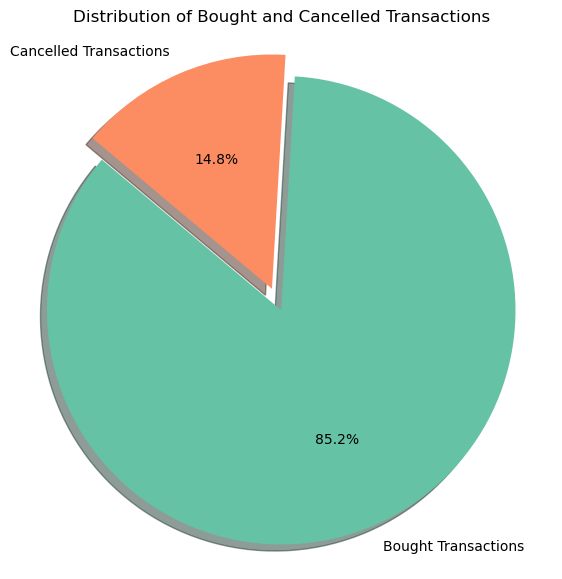

In [31]:
#adds labels for transactions
labels = ['Bought Transactions', 'Cancelled Transactions']

#adds sizes for the pie chart
sizes = [num_bought, num_cancelled]

#explodes parameter to highlight a segment
explode = (0.1, 0)  # only "explode" the first slice

#adds colors for the pie chart
colors = ['#66c2a5', '#fc8d62']

#creates the pie chart
plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Distribution of Bought and Cancelled Transactions')
plt.show()

#### *Insight* 

The total number of unique transactions in the dataset is 25,900 which occurred between 01/12/2010 and 09/12/2011. Each transaction represents a unique invoice number which means it includes the total count of purchases and cancellations made during the time frame. Meanwhile, there is a total number of 22,064 bought transactions wherein customers have successfully completed their orders. The number of canceled transactions are invoice numbers that start with 'C', with 3,836 transactions. It is apparent in the pie graph that 85% of the transactions were successful and only 14.8% were canceled. This suggests that the majority of the customers followed through with their orders, however, an approximate 15% cancellation rate can be relatively high depending on the industry. It is recommended to find out why these cancellations happen and can be a signal for the business to figure out and take action. 

**2. How many unique customers are there?**

In [34]:
#gets the unique customers
unique_customers = retail['CustomerID'].nunique()

print(f'Number of unique customers: {unique_customers}')

Number of unique customers: 4372


#### *Insight* 

In the dataset, there is a total of 4,372 unique customers. According to Chen (2015), many of these customers in the dataset are wholesalers. Although the number of unique customers is not very large compared to the number of transactions, the presence of wholesalers indicates that these customers buy products in bulk, which contributes a lot to the company's sales.

#### 4.2 Sales Analysis

**1. What are the top 5 best-selling products?**

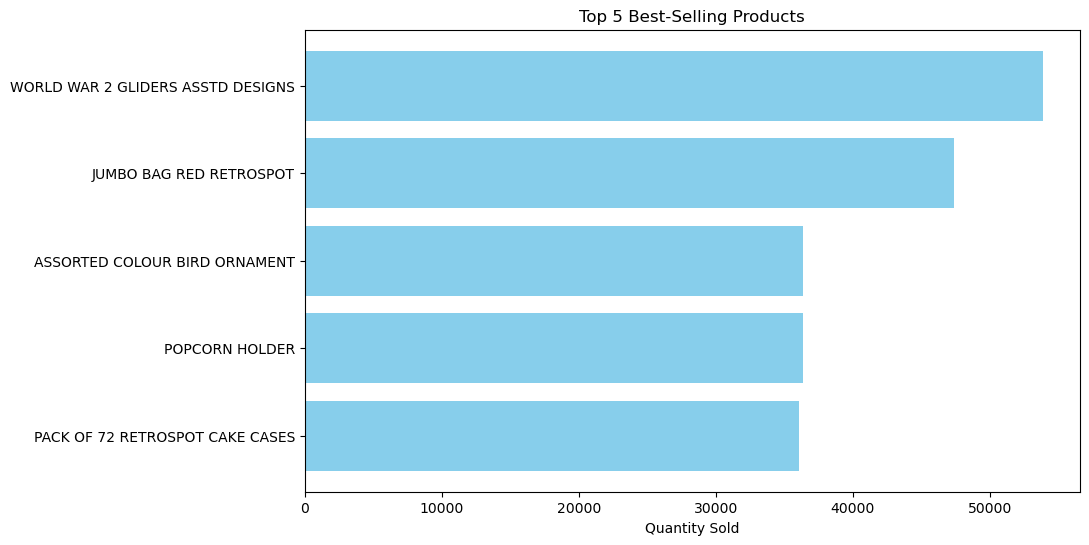

,Product Description,Quantity Sold
4009,WORLD WAR 2 GLIDERS ASSTD DESIGNS,53847
1866,JUMBO BAG RED RETROSPOT,47363
244,ASSORTED COLOUR BIRD ORNAMENT,36381
2740,POPCORN HOLDER,36334
2395,PACK OF 72 RETROSPOT CAKE CASES,36039


In [116]:
#groups and sorts the products 
top_products = retail.groupby('Description')['Quantity'].sum().reset_index()
top_products = top_products.sort_values(by='Quantity', ascending=False).head(5)

#creates the bar graph
plt.figure(figsize=(10, 6))
plt.barh(top_products['Description'], top_products['Quantity'], color='skyblue')
plt.xlabel('Quantity Sold')
plt.title('Top 5 Best-Selling Products')
plt.gca().invert_yaxis()
plt.show()

#displays the table
top_products.columns = ['Product Description', 'Quantity Sold']
display(top_products)

#### *Insight* 

It is evident from the table and the bar chart that the World War 2 Gliders Assorted Designs dominates in the dataset with a profound quantity sold of 53,847. This means that most of the customers have an interest in themed or novelty items related to Word War 2. Following this is the Jumbo Bag Red Retrospot with 47,363 items sold. The next items, are an Assorted Colour Bird Ornament, Popcorn Holder, and Pack of 72 Retrospot Cake Cases which vary closely in the amount of quantity sold, around 36,000. Given the high sales volume, it is critical to ensure the inventory levels of these top 5 best-selling products are in continuously restocked to maintain availability. 

**2. Which countries generate the most revenue?**

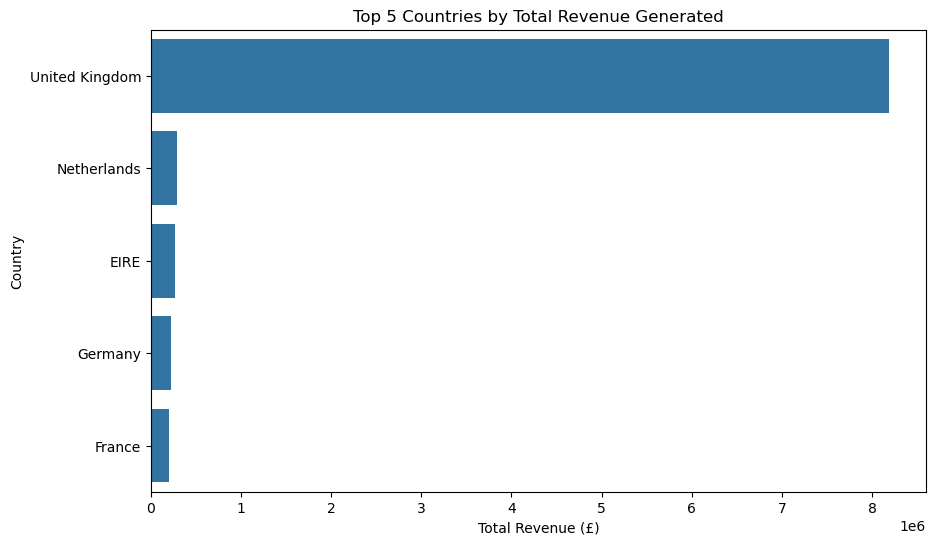

Top 5 highest revenue countries:


,Country,Revenue
36,United Kingdom,8187806.364
24,Netherlands,284661.540
10,EIRE,263276.820
14,Germany,221698.210
13,France,197403.900


In [41]:
#calculates revenue for each transaction
retail['Revenue'] = retail['Quantity'] * retail['UnitPrice']

#groups by country and sums the revenue for each country
country_revenue = retail.groupby('Country')['Revenue'].sum().reset_index()

#sorts the countries by total revenue in descending order
country_revenue = country_revenue.sort_values(by='Revenue', ascending=False)

#gets the top 5 countries with the highest revenue
top_5_countries = country_revenue.head(5)

#plots a bar chart for the 5 countries by total revenue
plt.figure(figsize=(10, 6))
sns.barplot(x='Revenue', y='Country', data=top_5_countries)
plt.title('Top 5 Countries by Total Revenue Generated')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.show()

print('Top 5 highest revenue countries:')
top_5_countries

#### *Insight* 

The country that generates the most revenue is the United Kingdom, contributing 8,187,806.364 pounds, with a very large gap compared to all the countries. It has a difference of 7,903,1405 pounds from the second-highest revenue country, the Netherlands. This data suggests that the UK market is the main focus of the sales and marketing efforts. The Netherlands, EIRE/Ireland, Germany, and France collectively contribute substantial revenue but the figures are significantly lower than the UK. These countries' revenues range from 197,403 pounds to 284,661 pounds.  However, these four countries still have potential opportunities for market growth. 

#### 4.3 Customer Behavior

**1. What is the average number of products per transaction?**

In [45]:
#groups by invoice and sums quantity for each transaction
product_transaction = retail.groupby('InvoiceNo')['Quantity'].sum()

#calculates the average of total products per transaction
avg_product_transaction = product_transaction.mean()

#prints the average number of products in transactions
print(f'The average number of products per transaction is: {avg_product_transaction:.2f}')

The average number of products per transaction is: 199.86


#### *Insight* 

The average number of products per transaction is nearly 200, which reveals that the majority of the customers purchase in large quantities. This argument is true since it is stated in the dataset information that most of them are wholesalers. This also means that the product offerings by the company are more appealing and intended for buyers seeking bulk purchases that also restock their inventory. With that, the retailer knows that they should align marketing and product efforts effectively with wholesalers. Inventory levels must be closely monitored since a high number of products per transaction can lead to stockouts if neglected. 

**2. What does the average spend per customer?**

In [48]:
#calculates the revenue by multiplying quantity with unit price
retail['Revenue'] = retail['Quantity'] * retail['UnitPrice']

#groups by customer ID and sums revenue for each customer
customer_revenue = retail.groupby('CustomerID')['Revenue'].sum().reset_index()

#calculates the average spend per customer
average_spend = customer_revenue['Revenue'].mean()

#prints the average spend per customer
print(f'The average spend per customer is: £{average_spend:.2f}')

The average spend per customer is: £1898.46


#### *Insight* 

The average spend per customer, 1898.46 pounds, suggests that the customers are willing to invest profoundly in the business products and could be a reflection of customer loyalty and the high customer value of the business. The business may focus on improving its products, cultivating customer relationships, and giving incentives/benefits for high-value customers in order to enhance customer retention. These strategies will drive higher sales and average spending per customer.

***
### How can the online retailer increase profits by analyzing buying habits and implementing personalized, targeted marketing strategies for different customer segments?

#### 1. Customer Segmentation

**What are the key characteristics that differentiate high-value customers from low-value customers, and how can we effectively segment them?**

In [52]:
#creates a new column for total spending
retail['TotalSpending'] = retail['Quantity'] * retail['UnitPrice']

#groups by customer ID to get total spending, purchase frequency, and total quantity
customer_summary = retail.groupby('CustomerID').agg(
    TotalSpending=('TotalSpending', 'sum'),
    PurchaseFrequency=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum')
).reset_index()

#defines thresholds for high-value and low-value customers
high_value_threshold = customer_summary['TotalSpending'].quantile(0.75)
low_value_threshold = customer_summary['TotalSpending'].quantile(0.25)

#categorizes customers based on spending
customer_summary['CustomerValue'] = pd.cut(
    customer_summary['TotalSpending'],
    bins=[-1, low_value_threshold, high_value_threshold, float('inf')],
    labels=['Low-Value', 'Medium-Value', 'High-Value']
)

#calculates average characteristics for each customer value category
key_characteristics = customer_summary.groupby('CustomerValue', observed=True).agg(
    AvgTotalSpending=('TotalSpending', 'mean'),
    AvgPurchaseFrequency=('PurchaseFrequency', 'mean'),
    AvgTotalQuantity=('TotalQuantity', 'mean')
).reset_index()

key_characteristics

,CustomerValue,AvgTotalSpending,AvgPurchaseFrequency,AvgTotalQuantity
0,Low-Value,169.365124,1.423004,122.628327
1,Medium-Value,738.841845,3.120769,452.785453
2,High-Value,5965.246634,12.633120,3467.205855


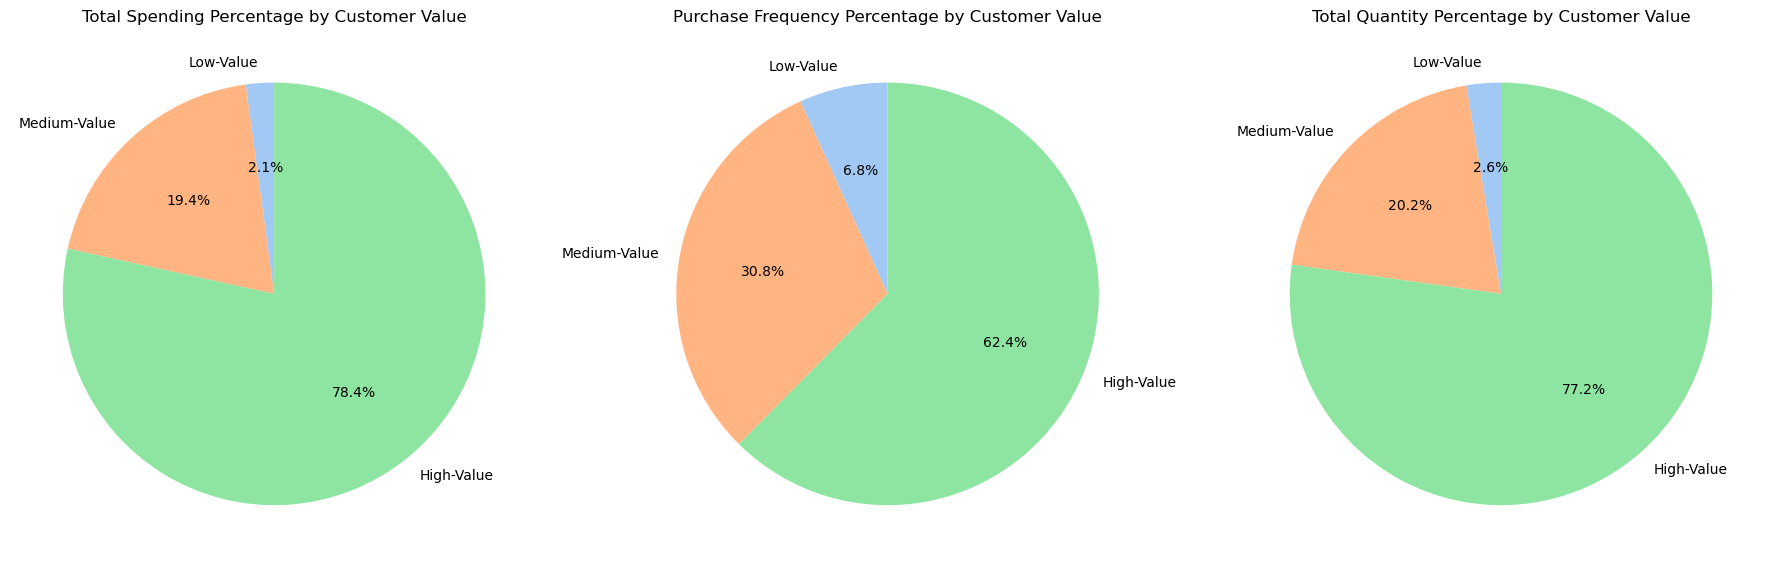

In [122]:
plt.figure(figsize=(18, 6))

#First Pie Chart: Total Spending Percentage
plt.subplot(1, 3, 1)
plt.pie(segment_sums['SpendingPercentage'], labels=segment_sums['CustomerValue'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Total Spending Percentage by Customer Value')

#Second Pie Chart: Purchase Frequency Percentage
plt.subplot(1, 3, 2)
plt.pie(segment_sums['PurchaseFrequencyPercentage'], labels=segment_sums['CustomerValue'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Purchase Frequency Percentage by Customer Value')

#Third Pie Chart: Total Quantity Percentage
plt.subplot(1, 3, 3)
plt.pie(segment_sums['QuantityPercentage'], labels=segment_sums['CustomerValue'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Total Quantity Percentage by Customer Value')

plt.tight_layout()
plt.show()

#### *Insight* 

Customer segmentation is crucial in understanding different customer characteristics and identifying which customer groups drive profitability (Jolaoso, 2024). Knowing these customer segments helps in prioritizing marketing strategies that resonate with them distinctively. 

It is evident that the percentage of total spending of high-value customers is 78.4% with a significantly high purchase frequency percentage of 62.4%. In terms of the total quantity, high-value customers also dominate in the dataset with 77.2% of products purchased. These results indicate that there is a strong loyalty among high-value customers and have deeper engagement with the business compared to low-value and medium-value customers. For this segment, maintaining customer satisfaction is crucial. Offering personalized benefits, emails, and rewards for their loyalty, will ensure that they continue to purchase and engage with the brand more frequently. An example of retaining high-value customers is Sephora's Tiered Loyalty Program. Sephora offers high-tier members early access to their new products, personalized makeup services, and access to product events (Lindecrantz, 2020). In short, retaining high-value customers is critical based on the data. 

Medium-value customers spend a total of 19.4%, with a  frequent purchase of 30.8%, and purchase 20.2% of products. This segment is performing slightly better than the low-value customers but improvements can be made in terms of upselling and customer engagement. Therefore, implementing personalized marketing strategies, and cross-selling opportunities, urge medium-value customers to transition to high-value. An example of personalized marketing strategies is Franklin Sports' One-on-One product recommendations (Expert Panel, 2021). The company used machine learning to deliver one-on-one product recommendations across channels based on each customer's interests, behavior, and recent transactions instead of exposing customers to a pre-determined experience.

Lastly, low-value customers have a very low percentage of total spending at 2.1% with seldom purchases at about 6.8%, and bought low quantities, at a 2.6%. This strongly suggests that the business must also focus on increasing the satisfaction or engagement of low-value customers and not solely focus on high-value ones. Attracting and acquiring customers is a critical part of the survival of the business, besides retention. The business must implement strategies to encourage higher spending and frequency in this segment. According to Petersen (2017), Amazon has started to pay close attention to Customer Lifetime Value (CLV) in order to keep every customer segment engaged, most especially low-value customers. It also indicates that price must be competitive in order to make a mark in the market and potentially convert low-value into a higher segment. Other brands that use Customer Lifetime Values are Bonobos, Crocs, Starbucks, Netflix, and other successful companies. 

#### 2. Product Association

**Which products are most frequently purchased together, and how can this information inform cross-selling strategies?**

In [56]:
#the following functions are imported to generate frequent itemsets from transactional data, 
#and measure the presence of items like support, confidence, and lift
from mlxtend.frequent_patterns import apriori, association_rules

#preprocesses the data to create a basket matrix
basket = (retail
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

#checks the presence/absence of product
basket = basket.applymap(lambda x: 1 if x > 0 else 0).astype(bool)

#generates frequent itemsets
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)

#generates association rules based on lift
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

#sorts rules by lift
rules = rules.sort_values(by='lift', ascending=False)

#displays the top product associations
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20)

C:\Users\Amanda\AppData\Local\Temp\ipykernel_15036\704312861.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  basket = basket.applymap(lambda x: 1 if x > 0 else 0).astype(bool)


,antecedents,consequents,support,confidence,lift
1373,(REGENCY TEA PLATE PINK),"(REGENCY TEA PLATE GREEN , REGENCY TEA PLATE R...",0.010431,0.836066,64.070404
1368,"(REGENCY TEA PLATE GREEN , REGENCY TEA PLATE R...",(REGENCY TEA PLATE PINK),0.010431,0.799373,64.070404
1370,"(REGENCY TEA PLATE ROSES , REGENCY TEA PLATE P...",(REGENCY TEA PLATE GREEN ),0.010431,0.947955,60.823405
1371,(REGENCY TEA PLATE GREEN ),"(REGENCY TEA PLATE ROSES , REGENCY TEA PLATE P...",0.010431,0.669291,60.823405
794,(REGENCY TEA PLATE GREEN ),(REGENCY TEA PLATE PINK),0.011372,0.729659,58.482750
795,(REGENCY TEA PLATE PINK),(REGENCY TEA PLATE GREEN ),0.011372,0.911475,58.482750
1372,(REGENCY TEA PLATE ROSES ),"(REGENCY TEA PLATE GREEN , REGENCY TEA PLATE P...",0.010431,0.573034,50.389863
1369,"(REGENCY TEA PLATE GREEN , REGENCY TEA PLATE P...",(REGENCY TEA PLATE ROSES ),0.010431,0.917266,50.389863
798,(REGENCY TEA PLATE ROSES ),(REGENCY TEA PLATE PINK),0.011004,0.604494,48.450720
799,(REGENCY TEA PLATE PINK),(REGENCY TEA PLATE ROSES ),0.011004,0.881967,48.450720


#### *Insight* 

Product association is done to analyze which products are commonly bought together by customers, which would be insightful for increasing sales through cross-selling strategies effectively (geekspeak, 2023). This code block effectively determines and ranks the most important product associations, also called market basket analysis. Aside from cross-selling, this will greatly help in product placement and creating promotions for the business. 

A noticeable strong product pairing is the Regency Tea Plate products wherein come in different variations such as Roses, Pink, and Green which are frequently bought together. It also shows in the result of support and confidence values. The combination of Regency Tea Plate Roses and Pink has the highest lift value of 64.07 which indicates a strong correlation that customers purchase one product and instinctively buy the other. Aside from the Regency Tea Plates variation, Poppy's Playhouse has significant associations with its variations such as Living Room, Bedroom, and Kitchen products. This speaks a lot about the customers and cohesive product offerings are appealing to them. The next combination is the Set of Red Spotty Paper Plates and the Set of Red Retrospot Paper Napkins. This combination emphasizes more on functionality, as a customer who buys paper plates is likely to buy paper napkins along with them, both being related to mealtime. 

The results prove that several of the product associations fall under similar themes or like a gift set wherein it attracts a lot of customers. With that, focusing more on promoting themed collections may increase average order value or sales. Marketing campaigns must also be tailored according to the insights found in product associations. For example, email and website recommendations could highlight frequently paired products to encourage them to buy larger orders. In addition, bundling these associations and offering discounts could significantly enhance sales, especially for low-value customers who may think that the prices of the products are expensive. Gaining an understanding of product associations greatly helps in inventory management since it ensures that combinations of products must be continuously stocked together. 

#### 3. Purchasing Patterns

**Which products do different customer groups buy the most?**

Top products bought by customer segments:
      CustomerValue                        Description  Quantity
194       Low-Value     ASSTD DESIGN 3D PAPER STICKERS     12664
1040      Low-Value    GIRLS ALPHABET IRON ON PATCHES       1440
174       Low-Value          ASSORTED COLOURS SILK FAN      1200
6403   Medium-Value  WORLD WAR 2 GLIDERS ASSTD DESIGNS      8584
3100   Medium-Value      ASSORTED COLOUR BIRD ORNAMENT      7759
3395   Medium-Value                BROCADE RING PURSE       6432
10141    High-Value  WORLD WAR 2 GLIDERS ASSTD DESIGNS     43995
8177     High-Value            JUMBO BAG RED RETROSPOT     40666
8661     High-Value    PACK OF 72 RETROSPOT CAKE CASES     28243


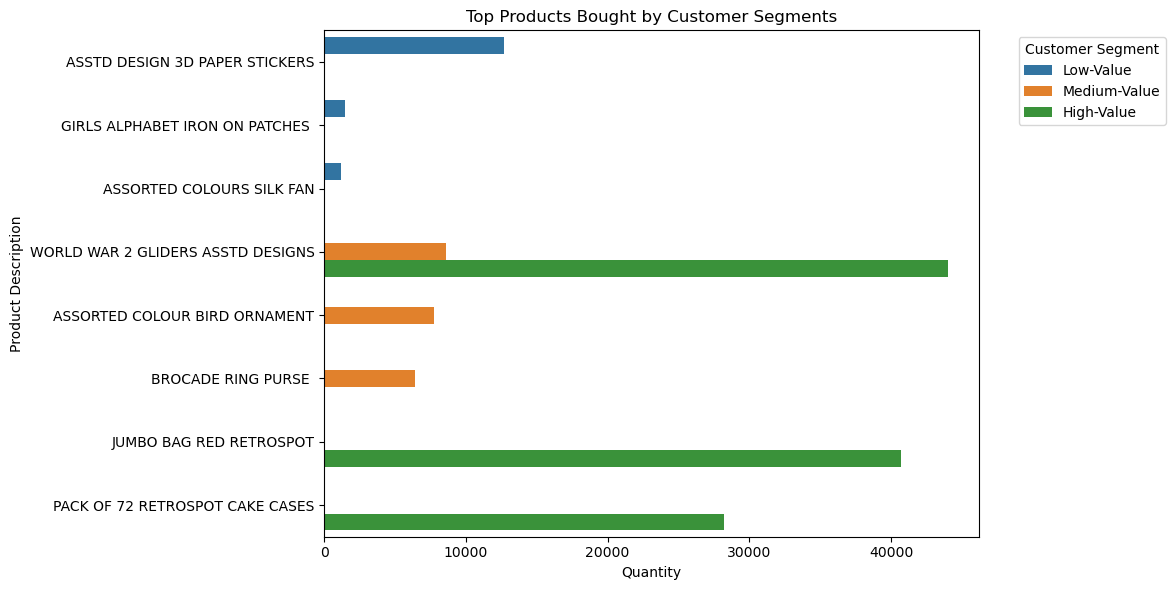

In [59]:
#groups data by customerID and description then sums the quantity
grouped_data = retail.groupby(['CustomerID', 'Description']).agg({'Quantity': 'sum'}).reset_index()

#merges with customer_summary to get the CustomerValue
merged_data = pd.merge(grouped_data, customer_summary[['CustomerID', 'CustomerValue']], on='CustomerID')

#groups by CustomerValue and Description to get total quantities
grouped_data = merged_data.groupby(['CustomerValue', 'Description'], observed=True).agg({'Quantity': 'sum'}).reset_index()

#sorts the data to get the most purchased products for each customer segment
sorted_data = grouped_data.sort_values(['CustomerValue', 'Quantity'], ascending=[True, False])

#gets the top N products for each customer segment 
top_n = 3
top_products = sorted_data.groupby('CustomerValue', observed=True).head(top_n)

print("Top products bought by customer segments:")
print(top_products)

#creates a bar plot for visualization of top products
plt.figure(figsize=(12, 6))
sns.barplot(x='Quantity', y='Description', hue='CustomerValue', data=top_products, dodge=True)
plt.title('Top Products Bought by Customer Segments')
plt.xlabel('Quantity')
plt.ylabel('Product Description')
plt.legend(title='Customer Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### *Insight* 

The graph shows the top 3 products bought by different customer segments in order to analyze their distinct purchasing patterns. 

It presents in the bar graph that high-value customers (green bar) purchase bulk quantities of products such as World War 2 Gliders Assorted Designs, Jumbo Bag Red Retrospot, and Pack of 72 Retrospot Cake Cases. World War 2 Gliders Assorted Designs is the most purchased possibly because they have a great preference for themed items and the product might be worth it for its price and design. The same goes well with the Jumbo Bag RetroSpot with a high purchase value of 40,666 quantities while the Pack of 72 Retrospot Cake Cases has approximately 28,243 quantities sold. Both of these products are more practical and functional compared to the World War 2 Gliders Assorted Designs. The inventory levels of these products must be monitored consistently by the retailer. 

Next, the top 3 products of medium-value customers (orange bar) are the World War 2 Gliders Assorted Designs, Assorted Colour Bird Ornament, and Brocade Ring Purse. It reveals that World War 2 Gliders is in fact highly purchased by both medium and high-value customers. On the other hand, bird ornament is more of an aesthetic or ornamental item, while the ring purse might be more useful and functional for this segment. 

Lastly, low-value customers significantly high quantities of Assorted Design 3D Paper stickers. A significant difference in quantities noticeable next to these stickers is the Girls Alphabet Iron On Patches and Assorted Colours Silk Fan. These are probably smaller and more likely cost-effective items that are more appealing and useful to this segment. 

Overall, it can be concluded that high-value customers are responsible for the wholesale of popular items. Medium-value and low-value customers focus more on aesthetics and functional products. To increase profits, the retailer can improve the marketing and product availability for high-value customers while also developing targeted marketing strategies to upsell and stand out to Medium and Low-Value customers. They can take action by improving their product offering, providing dynamic pricing, and better-targeted campaigns. 

#### 4. Geographic Influence

**Are there geographic patterns in purchasing behavior to improve targeted marketing?**

In [155]:
# creates the table 
table = top_10_countries[['Country', 'TotalSpending', 'PurchaseFrequency', 'TotalQuantity']]

# sets the decimal place into 2 for the original metrics
pd.options.display.float_format = '{:.2f}'.format  

table

,Country,TotalSpending,PurchaseFrequency,TotalQuantity
36,United Kingdom,8187806.36,23494,4263829
24,Netherlands,284661.54,101,200128
10,EIRE,263276.82,360,142637
14,Germany,221698.21,603,117448
13,France,197403.90,461,110480
0,Australia,137077.27,69,83653
33,Switzerland,56385.35,74,30325
31,Spain,54774.58,105,26824
3,Belgium,40910.96,119,23152
32,Sweden,36595.91,46,35637


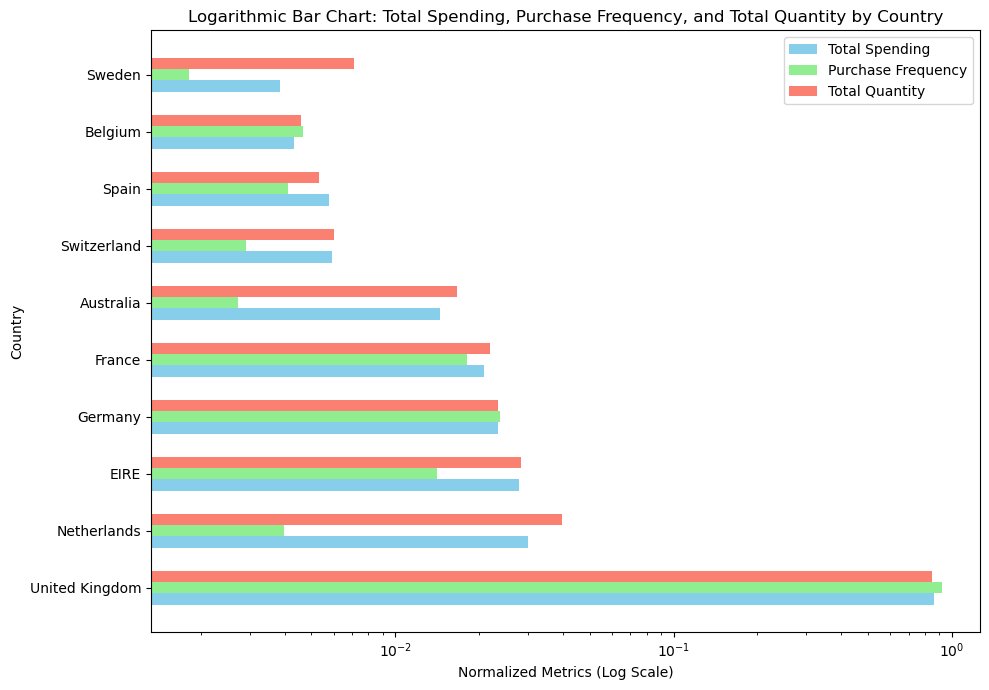

In [166]:
#ensures that all metrics are normalized to fit into the same range for the stacked bar chart
top_10_countries.loc[:, 'TotalSpendingNorm'] = top_10_countries['TotalSpending'] / top_10_countries['TotalSpending'].sum()
top_10_countries.loc[:, 'PurchaseFrequencyNorm'] = top_10_countries['PurchaseFrequency'] / top_10_countries['PurchaseFrequency'].sum()
top_10_countries.loc[:, 'TotalQuantityNorm'] = top_10_countries['TotalQuantity'] / top_10_countries['TotalQuantity'].sum()

#creates a horizontal bar chart with logarithmic scale
plt.figure(figsize=(10, 7))

#plots the normalized metrics as separate bars for clarity
bar_width = 0.2  
y_positions = np.arange(len(top_10_countries['Country']))

#Total Spending
plt.barh(y_positions, top_10_countries['TotalSpendingNorm'], color='skyblue', label='Total Spending', height=bar_width)

#Purchase Frequency
plt.barh(y_positions + bar_width, top_10_countries['PurchaseFrequencyNorm'], color='lightgreen', label='Purchase Frequency', height=bar_width)

#Total Quantity
plt.barh(y_positions + 2 * bar_width, top_10_countries['TotalQuantityNorm'], color='salmon', label='Total Quantity', height=bar_width)

# Titles and labels
plt.title('Logarithmic Bar Chart: Total Spending, Purchase Frequency, and Total Quantity by Country')
plt.xlabel('Normalized Metrics (Log Scale)')
plt.ylabel('Country')
plt.yticks(y_positions + bar_width, top_10_countries['Country'])
plt.xscale('log')  # Set the x-axis to a logarithmic scale
plt.legend()

plt.tight_layout()
plt.show()

#### *Insight* 

Analyzing the sales data in different countries can help cater to cultural preferences and may help tailor promotions and offer discounts on products that appeal more to local tastes. The company can also optimize its product offerings based on the countries' demand wherein some products are only popular in specific areas. However, this graph is more focused on the total spending, number of purchases, and total quantity to see the ratio and contribution of the countries to the revenue of the business.

It is apparent in the graph that the United Kingdom stands out significantly in total spending, purchase frequency, and quantity sold. Therefore, United Kingdom customers are the largest contributors to the revenue of the business, making them the primary consumers. The following countries, Netherlands, EIRE, Germany, France, and such are notably lower in all purchasing behaviors. Netherlands and EIRE have relatively great performance but are still significantly below the UK. This highlights that marketing efforts must prioritize the UK market due to its very high spending, repeat purchases, and substantial demand for products. The retailer must implement customer-centric marketing wherein they focus on giving loyalty programs or incentives for repeat customers in the UK. 

The other countries, Netherlands and Eire, are secondary targets wherein there is a potential for growth opportunities. The business must have a unique value proposition or brand recognition that will tap into the market of these countries and cater to their local needs. It is important for the business to assess its products first if they align well with the foreign market, making it easier to increase sales and build customer relationships with other countries. Also, if the products are similar or compete directly with many others at the same quality level, it is more difficult to increase profits. This could be addressed if there is a unique value proposition for the product. 

Since stepping up on the foreign market can be challenging and requires extensive preparation, it is important to research your target market, optimize your digital presence, partner with industry experts, and focus on quality assurance (Torres, 2023). Extensive research of the target country's market and understanding their cultural norms or local nuances are imperative to reach them effectively. With that, the business can keep up with the growing markets and potentially increase profits. 

#### Conclusion and Recommendation

To answer the main question, increased profits can be achieved if the online retailer focuses on targeted and personalized marketing strategies by utilizing customer segmentation, product association, purchasing patterns, and geographic influence insights. High-value customers can be retained through exclusive loyalty programs and early product access. Medium-value customers can be encouraged to purchase more through personalized product recommendations and cross-selling opportunities while low-value customers can be engaged with more competitive pricing, product bundles, and discounts to increase their purchase frequency and spending. It can also be concluded that Regency Tea Plates and Poppy's Playhouse product lines can be put into bundles for effective selling strategies. For geographical influence, the retailer must prioritize geo-targeted marketing in the UK since it is its largest revenue contributor while exploring potential opportunities in secondary markets like the Netherlands and Ireland. The retailer must also optimize the inventory to keep up with the demand for popular products to improve overall profitability. With that, continuous data analysis and machine learning techniques can further dig down and elaborate these personalized product strategies to ensure that the product offerings and promotions stay relevant for each customer segment. 

### **References**

UCI Machine Learning Repository. (2015) [Online] Uci.edu. Available from : https://archive.ics.uci.edu/dataset/352/online+retail [Accessed 19/09/24].

Daly, R. (2023) Leveraging Analytics and Big Data in Retail. [Online] AIM Consulting. Available from : https://aimconsulting.com/insights/retail-big-data-analytics-applications-benefits/ [Accessed 19/09/24].

Institute of Data (2023) How Can Data Analytics in Retail Benefit Businesses? | Institute of Data. [Online] Institute of Data. Available from : https://www.institutedata.com/blog/data-analytics-in-retail/ [Accessed 15/09/24].


Retail Demand Forecasting: How to Maximize Sales and Minimize Risks | Square. (2024) [Online] The Bottom Line by Square. Available from : https://squareup.com/us/en/the-bottom-line/operating-your-business/retail-demand-forecasting [Accessed 21/09/24].

Kumar, N. (2023) Big Data Analytics in Retail: Enhancing Customer Engagement. [Online] Analytics Insight. Available from : https://www.analyticsinsight.net/insights/big-data-analytics-in-retail-enhancing-customer-engagement [Accessed 21/09/24].

Quinn, A. (2023) 17 Best Free Retail Datasets for Machine Learning. [Online] Iguazio. Available from : https://www.iguazio.com/blog/13-best-free-retail-datasets-for-machine-learning/ [Accessed 21/09/24].

Big data and the supply chain: The big-supply-chain analytics landscape (Part 1). (2018) [Online] McKinsey & Company. Available from : https://www.mckinsey.com/capabilities/operations/our-insights/big-data-and-the-supply-chain-the-big-supply-chain-analytics-landscape-part-1 [Accessed 21/09/24].

Data Forest (2023) Big Data Analytics in Retail Industry: Real-Time Understanding. [Online] Dataforest.ai. Available from : https://dataforest.ai/blog/how-big-data-analytics-is-transforming-the-retail-industry [Accessed 21/09/24].

Expert Panel (2024) Council Post: 10 Great Examples Of Personalized Marketing Strategies. Forbes, 12 Aug.

Lindecrantz, E., Tjon, M. and Stefano Zerbi (2020) Personalizing the customer experience: Driving differentiation in retail. [Online] McKinsey & Company. Available from : https://www.mckinsey.com/industries/retail/our-insights/personalizing-the-customer-experience-driving-differentiation-in-retail [Accessed 21/09/24].

Deciphering Product Association: A Comprehensive Analysis  – Retail Taxonomy. (2023) [Online] Retailtaxonomy.com. Available from : https://retailtaxonomy.com/blog/deciphering-product-association-a-comprehensive-analysis[Accessed 21/09/24].

Jolaoso, C. (2024) Customer Segmentation: The Ultimate Guide. Forbes, 14 Jun.

Torres, E. and Torres, E. (2023) How to Tap Into International Markets and Grow Your Business. [Online] Lead Grow Develop. Available from : https://leadgrowdevelop.com/how-to-tap-into-international-markets-and-grow-your-business/ [Accessed 21/09/24].

Sakshi Deora (2023) Invoicing Basics: Everything You Need To Know. [Online] Refrens. Available from : https://www.refrens.com/grow/invoicing-basics [Accessed 21/09/24].

https://link.springer.com/content/pdf/10.1057/dbm.2012.17.pdf

Zhaina Rastrullo (2021) 5 Common data entry errors and ways to prevent them. [Online] Outsource Accelerator. Available from : https://www.outsourceaccelerator.com/articles/data-entry-error/ [Accessed 21/09/24].

Institute of Data (2023) How Can Data Analytics in Retail Benefit Businesses? | Institute of Data. [Online] Institute of Data. Available from : https://www.institutedata.com/blog/data-analytics-in-retail/ [Accessed 15/09/24].

What is Transactional Data? | TIBCO. (2024) [Online] TIBCO. Available from : https://www.tibco.com/glossary/what-is-transactional-da. [Accessed 21/09/24].

Amruta (2021) Market Basket Analysis: A Comprehensive Guide for Businesses. [Online] Analytics Vidhya. Available from : https://www.analyticsvidhya.com/blog/2021/10/a-comprehensive-guide-on-market-basket-analysis/ [Accessed 21/09/24].

‌admin (2024) What is Transactional Data? A Comprehensive Guide. [Online] Analytics Vivid: Exploring Big Data, AI, ML Trends, and News. Available from : https://analyticsvivid.com/understanding-transactional-data-a-comprehensive-guide/ [Accessed 21/09/24].

‌Saha, S. (2024) What is Customer Segmentation? The ULTIMATE Guide. [Online] Entropik.io. Available from : https://www.entropik.io/blogs/what-is-customer-segm20needs. [Accessed 21/09/24].

‌Tomar, A. (2020) Data Analytics in E-Commerce Retail | Towards Data Science. [Online] Medium. Available from : https://towardsdatascience.com/data-analytics-in-e-commerce-retail-7ea42b561c2f [Accessed 21/09/24].

‌Fuchs, J. (2020) Predictive Sales Analytics: Actionable Insight for Smarter Plans. [Online] Hubspot.com. Available from : https://blog.hubspot.com/sales/predictive-sa0companies. [Accessed 21/09/24].

‌Barron, J. (2024) 10 Common Data Quality Issues And How To Solve Them. [Online] Cognism.com. Available from : https://www.cognism.com/blog/data-quality-issues [Access 21/09/24].

‌
‌Baby, A. (2023) The Ultimate Guide to Data Cleaning: Ensuring Data Quality and Accuracy. [Online] Medium. Available from : https://medium.com/tech-tensorflow/the-ultimate-guide-to-data-cleaning-ensuring-data-quality-and-accuracy-8b9119c45aa4 [Accessed 21/09/24].

‌Kosinski, M. and Forrest, A. (2023) Data privacy. [Online] Ibm.com. Available from : https://www.ibm.com/topics/data-privacy [Accessed 21/09/24].

‌What is the General Data Protection Regulation (GDPR)? (2018) [Online] Cloudflare.com. Available from : https://www.cloudflare.com/learning/priir%20personal%20data. [ccessed 21/09/24].


‌paula (2023) Data Analytics Security and Its Use Cases: Protect Your Valuable Assets - Stefanini. [Online] Stefanini. Available from : https://stefanini.com/en/insights/news/data-analytics-security-and-its-use-cases-protect-your-valuable-assets [Accessed 21/09/24].

‌Why Retailers Fail to Adopt Advanced Data Analytics. (2023) [Online] Harvard Business Review. Available from : https://hbr.org/2023/02/why-retailers-fail-to-adopt-advanced-data-analytics [Accessed 21/09/24].

‌The Ethics of Managing People’s Data. (2023) [Online] Harvard Business Review. Available from : https://hbr.org/2023/07/the-ethics-of-managing-peoples-data [Accessed 21/09/24].

‌Reid, H. (2021) Complete Guide to Inventory Management Terms. [Online] DCL Logistics. Available from : https://dclcorp.com/blog/inventory/guide-inventory-management-terms/ [Accessed 21/09/24].

‌Tomar, A. (2020) Data Analytics in E-Commerce Retail | Towards Data Science. [Online] Medium. Available from : https://towardsdatascience.com/data-analytics-in-e-commerce-retail-7ea42b561c2f [Accessed 21/09/24].
GetOnData (2023) The Role of Data Analytics In Inventory Management. [Online] GetOnData. Available from : https://getondata.com/role-of-data-analytics-in-inventory-management/ [Accessed 21/09/24].

‌AKSHAY MESHRAM (2024) Seasonality Challenges in Demand Forecasting. [Online] Demand Forecasting & Supply Planning Blogs | Lite ThouSense. Available from : https://thousense.ai/blog/seasonality-challenges-in-demand-forecasting/ [Accessed 21/09/24].

‌Rosário, A.T. and Dias, J.C. (2023) How has data-driven marketing evolved: Challenges and opportunities with emerging technologies. International Journal of Information ManagData Insights, 3(2), p. 100203.

‌
‌
